# LABELING & FEATURE ENGINEERING

<h3>Cell 0 Import & Setup</h3>
<p>
Di tahap awal, kami mempersiapkan environment (numpy/pandas/matplotlib), set display option agar inspeksi kolom lebih nyaman, dan membaca dataset mentah <code>SPARC_dataset.csv</code> dari path yang sama dengan notebook (menggunakan <code>os.getcwd()</code>).
</p>
<p>
Hasilnya dataset berhasil terbaca dengan ukuran <b>319,978 baris</b> dan <b>28 kolom</b>. Kami juga melihat warning <i>DtypeWarning</i> yang mengindikasikan beberapa kolom bertipe campuran (mixed types). Ini wajar pada data real-world dan jadi sinyal bahwa kami harus melakukan cleaning/standardisasi tipe data pada tahap berikutnya.
</p>

In [1]:
import os
import re
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

csv_path = os.path.join(os.getcwd(), "SPARC_dataset.csv")
print("CSV path:", csv_path)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

CSV path: c:\Patrick\coding\save later\sparc\SPARC_dataset.csv
Shape: (319978, 28)


C:\Users\timot\AppData\Local\Temp\ipykernel_26180\1543217413.py:17: DtypeWarning: Columns (3,19,23,24,26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


,Customer ID,Kelurahan,Kecamatan,Kode POS,Cash/Credit,Kode Dealer,Finance Company,Tenor,Gender,Tgl Lahir,Agama,Pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,OTR,tahun rakit,DLR group,tgl cetak,tgl mohon,Kode Kota-Provinsi
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03 0:00:00,1,2e,27.0,Rp 21.000.000,Rp 8.600.000,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02-01-2019,6471-6400
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27 0:00:00,1,2b,28.0,87800000,20600000,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02012019,6471-6400
2,CUST-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-01-04 0:00:00,1,4b,37.0,Rp 0,Rp 0,MH,Balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02012019,6471-6400
3,CUST-164422,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1997-06-26 0:00:00,1,11,22.0,0,0,MH,Balikpapan,SCOOTY SERIES,krg 1 jt,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02012019,6471-6400
4,CUST-155472,Baru Ulu,Balikpapan Barat,76133,2.0,11160.0,1,2,1,1996-07-12 0:00:00,1,2e,23.0,21000000,12200000,MH,Balikpapan,SCOOTY SERIES,2 - 3 jt,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02-01-2019,6471-6400


<h3>Cell 1 - Quick Check (Info, Missing, Duplicates)</h3>
<p>
Di cell ini kami melakukan sanity check: melihat tipe data, persentase missing value, dan mengecek duplikasi baris persis sama.
</p>
<ul>
  <li>
    <b>Temuan missing value besar:</b> kolom <code>dlr group</code> missing sekitar <b>80.69%</b>.
    Ini artinya kolom tersebut bisa dipakai, tapi perlu strategi: treat sebagai kategori dengan banyak missing atau dipertimbangkan untuk tidak jadi fitur utama.
  </li>
  <li>
    <b>Duplikasi baris exact:</b> ditemukan <b>2,341</b> baris duplikat persis.
    Ini menjelaskan kenapa metrik “repeat per customer” bisa kelihatan janggal kalau hanya menghitung jumlah baris.
  </li>
  <li>
    <b>Issue kecil:</b> di awal cell kami sempat mengecek <code>customer id</code>, tetapi nama kolom di file masih “Customer ID” (case + spasi). Ini diselesaikan di cell berikutnya dengan standarisasi nama kolom.
  </li>
</ul>

In [2]:
# 1) Quick Check: info, missing, duplicates
display(df.info())

missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing_df = pd.DataFrame({"missing_%": missing, "missing_count": df.isna().sum()})
display(missing_df.head(20))

# cek duplikasi row 
dup_rows = df.duplicated().sum()
print("Duplicate rows (exact):", dup_rows)

# cek duplikasi customer id
if "customer id" in df.columns:
    cust_counts = df["customer id"].value_counts(dropna=False)
    print("Unique customer id:", cust_counts.shape[0])
    print("Customer repeat rate (customer muncul >1x):", (cust_counts.gt(1).mean()*100).round(2), "%")
else:
    print("Kolom 'customer id' tidak ditemukan. Cek nama kolom:", df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319978 entries, 0 to 319977
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Customer ID         319964 non-null  object 
 1   Kelurahan           319962 non-null  object 
 2   Kecamatan           319963 non-null  object 
 3   Kode POS            319963 non-null  object 
 4   Cash/Credit         319963 non-null  float64
 5   Kode Dealer         319963 non-null  float64
 6   Finance Company     319889 non-null  object 
 7   Tenor               319942 non-null  object 
 8   Gender              319962 non-null  object 
 9   Tgl Lahir           319963 non-null  object 
 10  Agama               319963 non-null  object 
 11  Pekerjaan           319963 non-null  object 
 12  umur                319963 non-null  float64
 13  dp aktual           319234 non-null  object 
 14  cicilan             319276 non-null  object 
 15  warna               319963 non-nul

None

,missing_%,missing_count
9 segment,0.004688,15
Agama,0.004688,15
Cash/Credit,0.004688,15
Customer ID,0.004375,14
DLR group,80.687110,258181
Finance Company,0.027814,89
Gender,0.005000,16
Kecamatan,0.004688,15
Kelurahan,0.005000,16
Kode Dealer,0.004688,15


Duplicate rows (exact): 2341
Kolom 'customer id' tidak ditemukan. Cek nama kolom: ['Customer ID', 'Kelurahan', 'Kecamatan', 'Kode POS', 'Cash/Credit', 'Kode Dealer', 'Finance Company', 'Tenor', 'Gender', 'Tgl Lahir', 'Agama', 'Pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'OTR', 'tahun rakit', 'DLR group', 'tgl cetak', 'tgl mohon', 'Kode Kota-Provinsi']


<h3>Cell 2 - Standarisasi Nama Kolom</h3>
<p>
Agar konsisten dan menghindari error karena perbedaan kapital/spasi, kami ubah semua nama kolom menjadi lowercase dan strip whitespace.
</p>
<p>
Hasilnya, kolom seperti <code>Customer ID</code> menjadi <code>customer id</code>, dan ini membuat seluruh pipeline (labeling, EDA, grouping) lebih stabil dan tidak mudah gagal karena mismatch nama kolom.
</p>

In [3]:
# 2) Standarisasi nama kolom
df.columns = [c.strip().lower() for c in df.columns]
print(df.columns.tolist())
df.head(2)

['customer id', 'kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'tgl lahir', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'tgl cetak', 'tgl mohon', 'kode kota-provinsi']


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03 0:00:00,1,2e,27.0,Rp 21.000.000,Rp 8.600.000,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02-01-2019,6471-6400
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27 0:00:00,1,2b,28.0,87800000,20600000,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02012019,6471-6400


<h3>Cell 3 - Cleaning Currency (dp aktual, cicilan)</h3>
<p>
Di data mentah, kolom seperti <code>dp aktual</code> dan <code>cicilan</code> berbentuk teks (mis. mengandung "Rp", titik pemisah ribuan, dsb). 
Kalau langsung dipakai untuk statistik/modeling, akan menyebabkan kolom dianggap <code>object</code> dan operasi numerik seperti mean/median bisa error.
</p>
<p>
kami bikin helper <code>currency_to_num()</code> yang mengambil digit saja, lalu convert menjadi float.
Hasilnya kedua kolom berhasil menjadi numerik dan bisa dihitung deskriptif statistiknya.
</p>
<p>
Catatan: karena kami hanya mengambil digit, nilai seperti "0" atau format aneh tetap akan masuk sebagai angka. Ini OK untuk baseline, tetapi bisa ditambah validasi outlier di tahap modeling.
</p>

In [4]:
# 3) Helper: bersihin currency jadi angka
def currency_to_num(x):
    """
    Contoh input:
    - "Rp 21.000.000" -> 21000000
    - "21.000.000" -> 21000000
    - 21000000 -> 21000000
    - "-" / "" / NaN -> NaN
    """
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "" or s.lower() in ["nan", "none", "-", "null"]:
        return np.nan
    # ambil digit saja
    digits = re.sub(r"[^\d]", "", s)
    if digits == "":
        return np.nan
    try:
        return float(digits)
    except:
        return np.nan

currency_cols = []
for c in ["dp aktual", "cicilan"]:
    if c in df.columns:
        currency_cols.append(c)

print("Currency columns found:", currency_cols)

for c in currency_cols:
    df[c] = df[c].map(currency_to_num)

df[currency_cols].describe().T if currency_cols else "Tidak ada kolom currency yang cocok."

Currency columns found: ['dp aktual', 'cicilan']


,count,mean,std,min,25%,50%,75%,max
dp aktual,319234.0,1.589836e+07,6.794624e+07,0.0,0.0,2100000.0,24000000.0,3.000000e+10
cicilan,319276.0,8.039088e+06,3.189562e+08,0.0,0.0,1425000.0,12700000.0,8.575233e+10


<h3>Cell 4 - Parser Tanggal (Fixed) + QC Parsing</h3>
<p>
Ini bagian krusial: dataset tidak menyediakan label, jadi label harus dibuat berdasarkan urutan waktu. Maka parsing <code>tgl mohon</code> harus benar.
</p>
<p>
Awalnya parsing sempat gagal karena format dominan ternyata <b>8 digit</b> seperti <code>19012019</code> (ddmmyyyy). Kalau diparse asal, bisa dibaca sebagai tahun 1901 atau dianggap format lain.
</p>
<p>
Solusinya: di helper <code>parse_mixed_date()</code>, untuk string 8 digit kami paksa mencoba <b>ddmmyyyy dulu</b> (<code>%d%m%Y</code>), baru kalau gagal mencoba <code>%Y%m%d</code>.
</p>
<p>
QC membuktikan perbaikan berhasil: dari data raw, gagal parse yang “raw ada isi tapi NaT” tinggal <b>1 baris</b> saja, yaitu nilai <code>319977</code> yang jelas bukan tanggal.
</p>
<ul>
  <li>Parsed <code>tgl mohon</code>: <b>69.48%</b> non-null datetime</li>
  <li>Parsed <code>tgl lahir</code>: <b>100%</b> non-null datetime</li>
  <li>Parsed <code>tgl cetak</code>: sangat kecil (sekitar <b>0.06%</b>) → kolom ini jarang terisi</li>
</ul>

In [5]:
# 4) Helper: parsing tanggal
def parse_mixed_date(x):
    if pd.isna(x):
        return pd.NaT

    if isinstance(x, (pd.Timestamp, np.datetime64)):
        return pd.to_datetime(x, errors="coerce")

    s = str(x).strip()
    if s == "" or s.lower() in ["nan", "none", "null", "-"]:
        return pd.NaT

    digits = re.sub(r"[^\d]", "", s)

    if len(digits) == 8 and digits.isdigit():
        dt1 = pd.to_datetime(digits, format="%d%m%Y", errors="coerce")
        if not pd.isna(dt1):
            return dt1
        dt2 = pd.to_datetime(digits, format="%Y%m%d", errors="coerce")
        return dt2

    return pd.to_datetime(s, errors="coerce", dayfirst=True)


date_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in df.columns]
print("Date columns found:", date_cols)

for c in date_cols:
    df[c] = df[c].map(parse_mixed_date)

for c in date_cols:
    ok = df[c].notna().mean() * 100
    print(f"Parsed {c}: {ok:.2f}% non-null datetime")


csv_path = os.path.join(os.getcwd(), "SPARC_dataset.csv")
raw = pd.read_csv(csv_path, usecols=["tgl mohon"], dtype={"tgl mohon": "string"})
parsed_raw = raw["tgl mohon"].map(parse_mixed_date)

bad_mask = raw["tgl mohon"].notna() & parsed_raw.isna()
bad = raw.loc[bad_mask, "tgl mohon"].astype(str)

print("\n--- QC raw tgl mohon ---")
print("Total rows (raw):", raw.shape[0])
print("Raw tgl mohon null %:", (raw["tgl mohon"].isna().mean() * 100))
print("Total gagal parse (raw ada isi tapi NaT):", bad.shape[0])
print("Persentase gagal parse:", round((bad.shape[0] / raw.shape[0] * 100), 4), "%")

if bad.shape[0] > 0:
    print("\nContoh nilai tgl mohon yang gagal parse (20 teratas):")
    display(bad.head(20).to_frame(name="tgl_mohon_raw"))

    print("\nDistribusi panjang string (top 10):")
    display(bad.str.len().value_counts().head(10).to_frame("count"))

    print("\nTop 20 nilai mentah yang paling sering muncul:")
    display(bad.value_counts().head(20).to_frame("count"))

Date columns found: ['tgl mohon', 'tgl cetak', 'tgl lahir']


C:\Users\timot\AppData\Local\Temp\ipykernel_26180\1495879426.py:22: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  return pd.to_datetime(s, errors="coerce", dayfirst=True)


Parsed tgl mohon: 69.48% non-null datetime
Parsed tgl cetak: 0.06% non-null datetime
Parsed tgl lahir: 100.00% non-null datetime

--- QC raw tgl mohon ---
Total rows (raw): 319978
Raw tgl mohon null %: 0.004375300801930133
Total gagal parse (raw ada isi tapi NaT): 1
Persentase gagal parse: 0.0003 %

Contoh nilai tgl mohon yang gagal parse (20 teratas):


,tgl_mohon_raw
319977,319977



Distribusi panjang string (top 10):


,count
tgl mohon,
6,1



Top 20 nilai mentah yang paling sering muncul:


,count
tgl mohon,
319977,1


<h3>Cell 5 - Labeling Target</h3>
<p>
Tujuan label: <b>0</b> jika customer tidak ada transaksi berikutnya, <b>1</b> jika ada transaksi setelah transaksi ini.
</p>
<p>
Masalah versi awal: kalau customer punya banyak baris di <b>tanggal yang sama</b> (duplicate administratif), metode “urutan transaksi” bisa memberi label <code>1</code> padahal tidak ada transaksi di masa depan (hanya duplikasi same-day).
</p>
<p>
Perbaikan: kami pakai definisi <b>strict later date</b>:
<code>label = 1 jika max(tgl_mohon_customer) &gt; tgl_mohon_row</code>.
Dengan ini, baris yang berada di tanggal maksimum customer akan selalu bernilai 0, meski duplicate same-day banyak.
</p>
<p>
Hasil labeling:
</p>
<ul>
  <li>Total rows tetap: <b>319,978</b></li>
  <li>Rows valid untuk label (customer id & tgl mohon ada): <b>222,314</b></li>
  <li>Distribusi label: <b>0 = 194,516</b>, <b>1 = 27,798</b>, <b>NaN = 97,664</b></li>
</ul>
<p>
NaN bukan error: itu karena <code>tgl mohon</code> kosong sehingga tidak bisa menentukan urutan waktu.
</p>
<p>
Kami juga dokumentasikan duplikasi key <code>(customer id + tgl mohon)</code> sebanyak <b>12,824</b>, untuk menjelaskan kenapa pendekatan strict later date diperlukan.
</p>

In [6]:
# 5) Labeling target
import numpy as np
import pandas as pd

print("Rows in df (should match CSV lines):", df.shape[0])

required_cols = ["customer id", "tgl mohon"]
missing_required = [c for c in required_cols if c not in df.columns]
print("Missing required cols:", missing_required)

df["label_repeat_next"] = np.nan

if len(missing_required) == 0:
    mask_valid = df["customer id"].notna() & df["tgl mohon"].notna()
    print("Rows with customer id & valid tgl mohon:", int(mask_valid.sum()))

    tmp = df.loc[mask_valid, ["customer id", "tgl mohon"]].copy()

    # hitung max date per customer
    tmp["max_tgl_mohon_customer"] = tmp.groupby("customer id")["tgl mohon"].transform("max")

    tmp["label_repeat_next"] = (tmp["max_tgl_mohon_customer"] > tmp["tgl mohon"]).astype(int)

    df.loc[tmp.index, "label_repeat_next"] = tmp["label_repeat_next"].values

    df.loc[tmp.index, "max_tgl_mohon_customer"] = tmp["max_tgl_mohon_customer"].astype("datetime64[ns]")

    print("\n--- Label distribution (label_repeat_next) ---")
    print(df["label_repeat_next"].value_counts(dropna=False))
    print("Sum of counts:", int(df["label_repeat_next"].value_counts(dropna=False).sum()), "| df rows:", df.shape[0])

    dup_key = df.duplicated(subset=["customer id", "tgl mohon"]).sum()
    print("Duplicate (customer id + tgl mohon) rows in df:", int(dup_key))

else:
    print("Tidak bisa buat label time-aware karena kolom wajib tidak lengkap.")

Rows in df (should match CSV lines): 319978
Missing required cols: []
Rows with customer id & valid tgl mohon: 222314

--- Label distribution (label_repeat_next) ---
label_repeat_next
0.0    194516
NaN     97664
1.0     27798
Name: count, dtype: int64
Sum of counts: 319978 | df rows: 319978
Duplicate (customer id + tgl mohon) rows in df: 12824


<h3>Cell 5B - QC Labeling (Validasi dengan Tanggal Unik)</h3>
<p>
Di sini kami memastikan bahwa label <code>1</code> hanya muncul pada customer yang benar-benar memiliki transaksi pada lebih dari satu tanggal.
</p>
<p>
Kami hitung <code>n_unique_dates</code> per customer, lalu cek “suspect cases”:
customer yang punya <code>label=1</code> tetapi hanya memiliki <code>1</code> tanggal unik.
</p>
<p>
Hasilnya sangat bagus: <b>suspect = 0</b>. Artinya labeling strict later date sudah konsisten dengan definisi repeat berdasarkan waktu, dan tidak tertipu oleh duplikasi same-day.
</p>
<p>
Tambahan insight: customer valid-date yang punya &gt;1 tanggal transaksi adalah <b>19,100</b> (~<b>9.92%</b>).
</p>

In [7]:
# 5B) QC Labeling: cek repeat per customer berbasis tanggal unik
import pandas as pd

mask_valid = df["customer id"].notna() & df["tgl mohon"].notna()
tmp = df.loc[mask_valid, ["customer id", "tgl mohon", "label_repeat_next"]].copy()

# jumlah tanggal unik per customer
tmp["n_unique_dates"] = tmp.groupby("customer id")["tgl mohon"].transform("nunique")

cust_unique_dates = tmp.groupby("customer id")["tgl mohon"].nunique()
print("Customer unik (valid date):", cust_unique_dates.shape[0])
print("Customer dengan >1 tanggal transaksi:", int((cust_unique_dates > 1).sum()),
      "(", round((cust_unique_dates > 1).mean() * 100, 2), "% )")

check = tmp.groupby("customer id").agg(
    any_label1=("label_repeat_next", "max"),
    n_unique_dates=("tgl mohon", "nunique")
).reset_index()

suspect = check[(check["any_label1"] == 1) & (check["n_unique_dates"] <= 1)]
print("Customer yang punya label=1 tapi cuma 1 tanggal unik (harusnya 0):", suspect.shape[0])
display(suspect.head(10))

Customer unik (valid date): 192510
Customer dengan >1 tanggal transaksi: 19100 ( 9.92 % )
Customer yang punya label=1 tapi cuma 1 tanggal unik (harusnya 0): 0


,customer id,any_label1,n_unique_dates


<h3>Cell 6 - EDA Insight Dasar</h3>
<p>
Setelah label terbentuk, kami hitung repeat-next rate pada data yang berlabel.
Hasilnya <b>12.50%</b> transaksi memiliki transaksi berikutnya (label=1), dan kami visualisasikan distribusi label untuk melihat imbalance.
</p>
<p>
Kami juga membuat fungsi <code>repeat_rate_by()</code> untuk melihat repeat rate berdasarkan fitur kategori seperti cash/credit, tenor, segment, dealer, wilayah, dll.
Ini membantu memilih fitur yang potensial untuk modeling dan juga memberi insight awal untuk laporan.
</p>
<p>
Catatan: untuk kategori dengan n sangat kecil, repeat rate bisa misleading (misalnya wilayah dengan n=1 → 100%).
Di notebook EDA lanjutan, kami tambahkan filter minimum sample agar lebih stabil.
</p>

Repeat-next rate (per transaksi, pada data berlabel): 12.50%


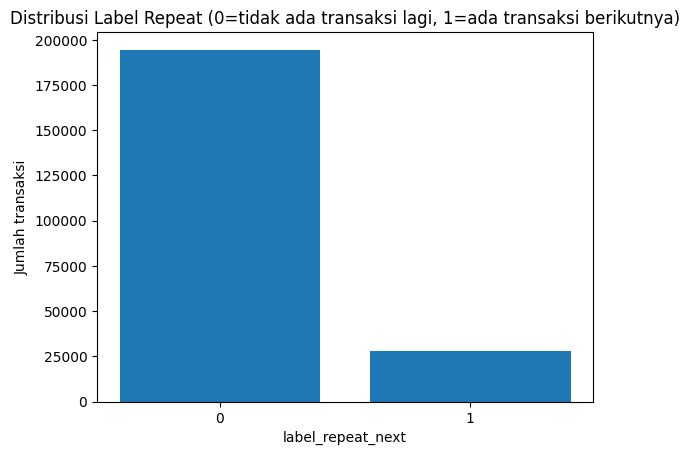

In [8]:
# 6) EDA Insight dasar terkait repeat
if "label_repeat_next" in df.columns:
    labeled = df[df["label_repeat_next"].notna()].copy()
    repeat_rate = labeled["label_repeat_next"].mean() * 100
    print(f"Repeat-next rate (per transaksi, pada data berlabel): {repeat_rate:.2f}%")

    # Plot distribusi label
    vc = labeled["label_repeat_next"].value_counts().sort_index()
    plt.figure()
    plt.bar(vc.index.astype(int).astype(str), vc.values)
    plt.title("Distribusi Label Repeat (0=tidak ada transaksi lagi, 1=ada transaksi berikutnya)")
    plt.xlabel("label_repeat_next")
    plt.ylabel("Jumlah transaksi")
    plt.show()

In [9]:
# 6.2 Insight awal: repeat rate per metode bayar (cash/credit), tenor, segment, dealer wilayah
def repeat_rate_by(col):
    if "label_repeat_next" not in df.columns:
        return None
    tmp = df[df["label_repeat_next"].notna()].copy()
    if col not in tmp.columns:
        print("Kolom tidak ada:", col)
        return None

    tab = (tmp.groupby(col)["label_repeat_next"]
             .agg(["count", "mean"])
             .rename(columns={"count": "n", "mean": "repeat_rate"}))
    tab["repeat_rate_%"] = tab["repeat_rate"] * 100
    tab = tab.sort_values("repeat_rate_%", ascending=False)
    return tab

for col in ["cash/credit", "tenor", "9 segment", "dealer", "wilayah", "dlr group", "finance company"]:
    if col in df.columns:
        print("\n=== Repeat rate by:", col, "===")
        tab = repeat_rate_by(col)
        display(tab.head(15))


=== Repeat rate by: cash/credit ===


,n,repeat_rate,repeat_rate_%
cash/credit,,,
1.0,97372,0.128312,12.831204
2.0,124942,0.122489,12.248883



=== Repeat rate by: tenor ===


,n,repeat_rate,repeat_rate_%
tenor,,,
4,120,0.291667,29.166667
1,26664,0.161679,16.167867
N,97341,0.128137,12.813717
2,75523,0.118679,11.867908
3,22647,0.088974,8.897426
5,3,0.000000,0.000000
6,3,0.000000,0.000000



=== Repeat rate by: 9 segment ===


,n,repeat_rate,repeat_rate_%
9 segment,,,
SPORT LOW,6794,0.463939,46.393877
CUB LOW,6395,0.260360,26.035966
SPORT HIGH,187,0.187166,18.716578
SPORT MID,9129,0.170884,17.088400
CUB HIGH,1815,0.169146,16.914601
CUB MID,4512,0.165559,16.555851
AT LOW,79011,0.110314,11.031375
EV AT HIGH,93,0.107527,10.752688
AT MID,76160,0.103020,10.301996


... (4 outputs left out)


=== Repeat rate by: dlr group ===


,n,repeat_rate,repeat_rate_%
dlr group,,,
SJX,3202,0.195503,19.550281
DAC,2523,0.174396,17.439556
MMX,2134,0.171978,17.197751
SX,22268,0.169705,16.970541
DMX,566,0.169611,16.961131
8X,812,0.168719,16.871921
TDX,3886,0.164951,16.495111
HV,5646,0.164010,16.400992
NSX,1324,0.157855,15.785498



=== Repeat rate by: finance company ===


,n,repeat_rate,repeat_rate_%
finance company,,,
11,4988,0.156375,15.637530
2,10118,0.145977,14.597747
13,1125,0.131556,13.155556
3,2458,0.130594,13.059398
N,97309,0.128272,12.827179
1,92857,0.122619,12.261865
9,1288,0.118012,11.801242
4,6457,0.091683,9.168344
36,734,0.081744,8.174387


<h3>Cell 6.3 - Insight Numerik vs Label</h3>
<p>
Kami bandingkan statistik numerik (dp aktual, cicilan, OTR, umur, tahun rakit) untuk label 0 vs 1.
Tujuan: melihat apakah ada kecenderungan nilai yang berbeda pada customer yang repeat.
</p>
<p>
Hasil awal menunjukkan beberapa perbedaan median yang cukup jelas (misalnya dp aktual dan cicilan median lebih tinggi pada label=1),
dan boxplot membantu memvisualisasikan perbedaan distribusi.
</p>
<p>
Catatan penting: ada outlier besar (max sangat tinggi) yang bisa mengganggu mean,
jadi median/quantile lebih dipercaya untuk insight.
Nanti di preprocessing modeling, outlier handling bisa dipertimbangkan (clipping / log transform).
</p>

Numeric cols found: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit']


label_repeat_next           0.0           1.0
dp aktual count    1.941670e+05  2.772200e+04
          mean     1.584712e+07  2.124157e+07
          std      4.965637e+07  1.826970e+08
          min      0.000000e+00  0.000000e+00
          25%      0.000000e+00  0.000000e+00
          50%      2.100000e+06  6.000000e+06
          75%      2.400000e+07  3.000000e+07
          max      1.810870e+10  3.000000e+10
cicilan   count    1.942040e+05  2.772700e+04
          mean     8.140135e+06  1.008680e+07
          std      3.512178e+08  1.832714e+08
          min      0.000000e+00  0.000000e+00
          25%      0.000000e+00  0.000000e+00
          50%      1.435000e+06  2.450000e+06
          75%      1.250000e+07  1.400000e+07
          max      8.575233e+10  2.300001e+10
otr       count    1.945140e+05  2.779600e+04
          mean     5.866062e+07  5.151368e+07
          std      8.406487e+07  7.741706e+07
          min      0.000000e+00  1.331000e+07
          25%      2.106000e+07  1.994000e+07
          50%      2.316000e+07  2.207000e+07
          75%      3.161000e+07  2.817000e+07
          max      9.301000e+08  8.280000e+08
umur      count    1.945160e+05  2.779800e+04
          mean     8.484994e+01  7.824365e+01
          std      1.250965e+02  1.179984e+02
          min      0.000000e+00  0.000000e+00
          25%      2.700000e+01  2.900000e+01
          50%      3.800000e+01  3.800000e+01
          75%      5.100000e+01  4.900000e+01
          max      1.230000e+03  1.120000e+03

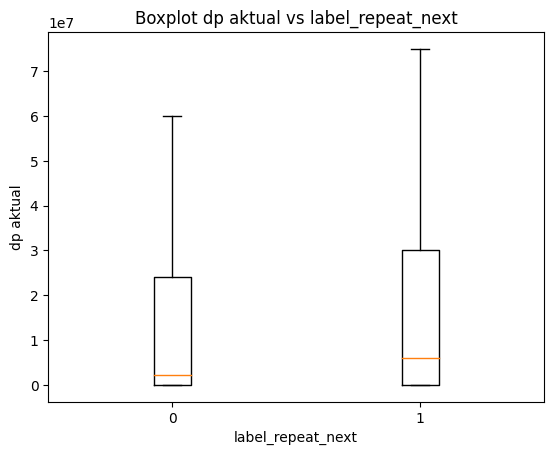

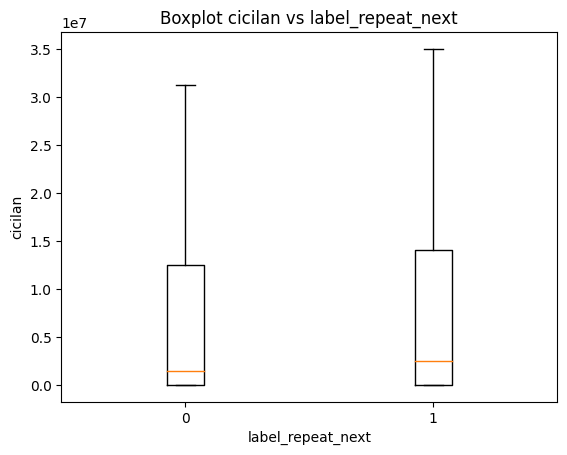

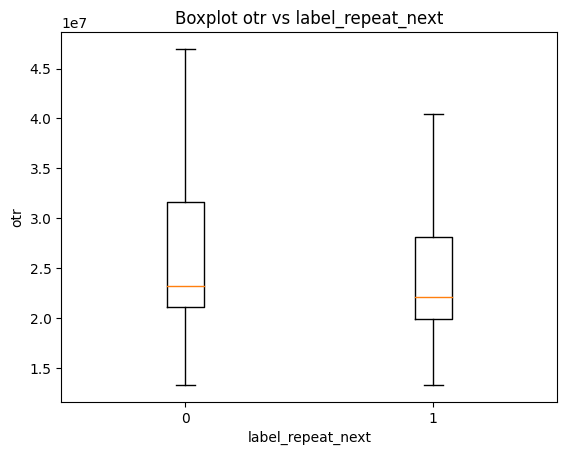

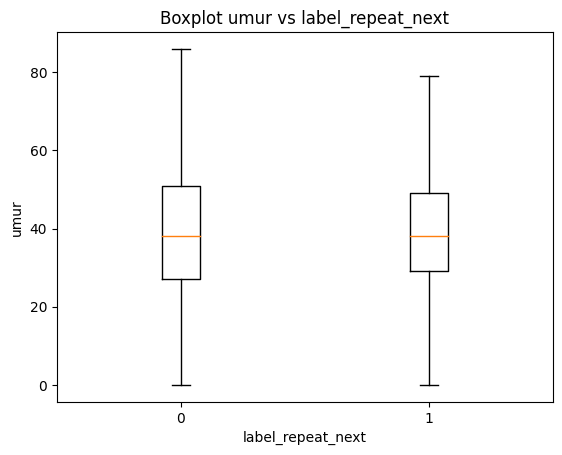

In [10]:
# 6.3 Insight numerik: hubungan dp/cicilan/OTR dengan repeat
num_cols = [c for c in ["dp aktual", "cicilan", "otr", "umur", "tahun rakit"] if c in df.columns]
print("Numeric cols found:", num_cols)

if "label_repeat_next" in df.columns and len(num_cols) > 0:
    tmp = df[df["label_repeat_next"].notna()].copy()

    summary = tmp.groupby("label_repeat_next")[num_cols].describe().T
    display(summary)

    for c in ["dp aktual", "cicilan", "otr", "umur"]:
        if c in tmp.columns:
            plt.figure()
            data0 = tmp.loc[tmp["label_repeat_next"] == 0, c].dropna()
            data1 = tmp.loc[tmp["label_repeat_next"] == 1, c].dropna()
            plt.boxplot([data0, data1], labels=["0", "1"], showfliers=False)
            plt.title(f"Boxplot {c} vs label_repeat_next")
            plt.xlabel("label_repeat_next")
            plt.ylabel(c)
            plt.show()

<h3>Cell 6.4 - Cek Potensi Data Leakage</h3>
<p>
Karena label dibuat dari informasi masa depan (transaksi setelah tanggal tertentu),
kami harus memastikan tidak ada fitur yang “membocorkan masa depan”.
</p>
<p>
Di pipeline kami, kolom helper seperti <code>tx_order</code> atau <code>tx_count_customer</code> tidak digunakan sebagai fitur.
Output menunjukkan daftar helper leakage kosong, jadi aman untuk lanjut.
</p>

In [11]:
# 6.4 Cek data leakage 
leak_cols = [c for c in ["tx_order", "tx_count_customer", "tgl_mohon_valid"] if c in df.columns]
print("Kolom helper (jangan dipakai untuk training kecuali jelas tersedia saat prediksi):", leak_cols)

Kolom helper (jangan dipakai untuk training kecuali jelas tersedia saat prediksi): []


<h3>PREP Cell A - Preprocessing untuk Modeling (Clean Types + Normalisasi Kategori)</h3>
<p>
Setelah proses labeling selesai, kami menambahkan tahap preprocessing ringan untuk menyiapkan dataset agar lebih konsisten saat
dipakai di seluruh model (LogReg, CatBoost, dan LightGBM).
Tahap ini mencakup:
</p>
<ul>
  <li><b>Normalisasi kolom kategorikal</b> (strip spasi, lowercase, hilangkan karakter aneh) khususnya untuk kolom yang bersifat ID-like agar kategori tidak terfragmentasi.</li>
  <li><b>Casting numerik</b> untuk fitur numerik yang sebelumnya berpotensi bertipe <i>object</i> (mis. currency/string) dengan <code>errors="coerce"</code>.</li>
  <li><b>Perapihan kolom noise</b> seperti fitur bin/kelas berbasis teks (mis. kolom yang mengandung kata <code>range</code>) agar tidak salah diproses sebagai numerik.</li>
</ul>
<p>
Tujuan utamanya adalah membuat pipeline modeling lebih ringkas dan mengurangi pengulangan preprocessing yang sebelumnya dilakukan di setiap notebook modeling.
</p>

In [12]:
df_labeled = df.copy()

# 1) Normalisasi kategori
def normalize_id_like(series: pd.Series) -> pd.Series:
    s = series.astype("string")
    s = s.str.strip().str.lower()
    s = s.str.replace(r"\s+", " ", regex=True)
    s = s.str.replace(r"[^\w\s\-\/]", "", regex=True)  # jaga supaya tidak terlalu agresif
    return s

# ambil kolom object sebagai kandidat kategori (exclude label & tanggal mentah)
cat_cols = [c for c in df_labeled.columns if df_labeled[c].dtype == "object"]
cat_cols = [c for c in cat_cols if c not in ["label_repeat_next"]]

# strip semua kategori
for c in cat_cols:
    df_labeled[c] = df_labeled[c].astype("string").str.strip()

# id-like: heuristic nama kolom
id_like_cols = [c for c in cat_cols if any(k in c.lower() for k in ["id", "kode", "code", "dealer", "branch", "cabang", "no"])]
id_like_cols = [c for c in id_like_cols if "tenor" not in c.lower()]  # tenor jangan dianggap id-like

for c in id_like_cols:
    df_labeled[c] = normalize_id_like(df_labeled[c])

# 2) Casting numerik (sesuaikan dengan kolom yang ada di dataset kamu)
numeric_keywords = ["dp", "cicil", "otr", "umur", "harga"]
num_cols = [c for c in df_labeled.columns if any(k in c.lower() for k in numeric_keywords)]
# hindari kolom bin seperti 'range dp'
num_cols = [c for c in num_cols if "range" not in c.lower()]

for c in num_cols:
    df_labeled[c] = pd.to_numeric(df_labeled[c], errors="coerce")

print("Preprocessing done.")
print("Kategori dibersihkan:", len(cat_cols), "| ID-like dinormalisasi:", len(id_like_cols))
print("Numerik di-cast:", num_cols)
display(df_labeled.head(3))
display(df_labeled.dtypes)

Preprocessing done.
Kategori dibersihkan: 19 | ID-like dinormalisasi: 5
Numerik di-cast: ['umur', 'dp aktual', 'cicilan', 'otr']


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
0,cust-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,1,2e,27.0,21000000.0,8600000.0,MC,balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,hn,18685000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,0.0,2019-01-02
1,cust-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,1,2b,28.0,87800000.0,20600000.0,MC,balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,hn,18685000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,0.0,2019-01-02
2,cust-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,1,4b,37.0,0.0,0.0,MH,balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,hr,20775000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,1.0,2020-08-25


customer id               string[python]
kelurahan                 string[python]
kecamatan                 string[python]
kode pos                  string[python]
cash/credit                      float64
kode dealer                      float64
finance company           string[python]
tenor                     string[python]
gender                    string[python]
tgl lahir                 datetime64[ns]
agama                     string[python]
pekerjaan                 string[python]
umur                             float64
dp aktual                        float64
cicilan                          float64
warna                     string[python]
dealer                    string[python]
type series               string[python]
range dp                  string[python]
wilayah                   string[python]
9 segment                 string[python]
kode motor                string[python]
otr                              float64
tahun rakit               string[python]
dlr group       

<h3>PREP Cell B - Feature Engineering Waktu dari <code>tgl mohon</code></h3>
<p>
Agar seluruh model memiliki fitur waktu yang konsisten, kami menurunkan beberapa fitur kalender dari kolom <code>tgl mohon</code>
(seperti tahun, bulan, hari dalam minggu, dan kuartal).
Fitur ini sering membantu model menangkap pola musiman atau perubahan perilaku repeat dari waktu ke waktu.
</p>
<p>
Fitur waktu ini dibuat <i>sekali</i> pada dataset berlabel sehingga tahap modeling tidak perlu mengulang proses yang sama pada setiap notebook.
</p>

In [13]:
# pastikan kolom tanggal utama sudah datetime dari proses parsing sebelumnya
date_col = "tgl mohon"
if date_col in df_labeled.columns:
    dt = pd.to_datetime(df_labeled[date_col], errors="coerce")
    df_labeled["mohon_year"] = dt.dt.year
    df_labeled["mohon_month"] = dt.dt.month
    df_labeled["mohon_dow"] = dt.dt.dayofweek
    df_labeled["mohon_quarter"] = dt.dt.quarter
else:
    print(f"Kolom {date_col} tidak ditemukan. Silakan sesuaikan date_col.")

display(df_labeled[[c for c in ["tgl mohon", "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"] if c in df_labeled.columns]].head(5))

,tgl mohon,mohon_year,mohon_month,mohon_dow,mohon_quarter
0,2019-01-02,2019.0,1.0,2.0,1.0
1,2019-01-02,2019.0,1.0,2.0,1.0
2,2019-01-02,2019.0,1.0,2.0,1.0
3,2019-01-02,2019.0,1.0,2.0,1.0
4,2019-01-02,2019.0,1.0,2.0,1.0


<h3>Save Dataset Berlabel</h3>
<p>
Agar workflow modular, kami simpan hasil dataset yang sudah dibersihkan dan diberi label ke file <code>sparc_labeled.csv</code>.
Ini membuat notebook EDA/modeling bisa langsung bekerja dari file siap pakai tanpa mengulang labeling.
</p>

In [15]:
# 7) Simpan dataset berlabel 
out_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df_labeled.to_csv(out_path, index=False)
print("Saved labeled data to:", out_path)

Saved labeled data to: c:\Patrick\coding\save later\sparc\sparc_labeled.csv
